# Airline Passenger & Flight Delay Analysis (2015 U.S. DOT)

An end-to-end data analytics pipeline examining **5,819,079** flight records across 14 U.S. airlines, covering data exploration, chunked Parquet data cleaning, exploratory data analysis (EDA), editorial pastel visualizations with crisp annotations, SQLite SQL queries, automated PDF reporting, and Power BI summary exports.

## 1. Environment Setup & Initial Data Inspection
Configure project paths, import libraries, and inspect schemas across `flights.csv`, `airlines.csv`, and `airports.csv`.

In [1]:
from pathlib import Path
import gc
import sqlite3
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

current_dir = Path.cwd()
project_dir = current_dir.parent if current_dir.name == "notebooks" else current_dir
raw_path = project_dir / "dataset" / "raw"
cleaned_path = project_dir / "dataset" / "cleaned"
viz_dir = project_dir / "visualizations"
sql_dir = project_dir / "sql"
reports_dir = project_dir / "reports"
pbi_dir = project_dir / "powerbi"

for folder in [cleaned_path, viz_dir, sql_dir, reports_dir, pbi_dir]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_dir)
print("Raw files available:", [f.name for f in sorted(raw_path.iterdir())])

Project folder: D:\Codenera\Project\Airline_Delay_Analysis
Raw files available: ['airlines.csv', 'airports.csv', 'flights.csv']


In [2]:
flights_sample = pd.read_csv(raw_path / "flights.csv", nrows=5)
airlines = pd.read_csv(raw_path / "airlines.csv")
airports = pd.read_csv(raw_path / "airports.csv")

print("Flights sample shape:", flights_sample.shape)
print("Airlines shape:", airlines.shape)
print("Airports shape:", airports.shape)
display(flights_sample)
display(airlines)

Flights sample shape: (5, 31)
Airlines shape: (14, 2)
Airports shape: (322, 7)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408,-22,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811,5,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259,-21,0,0,NaN,NaN,NaN,NaN,NaN,NaN


,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways
5,OO,Skywest Airlines Inc.
6,AS,Alaska Airlines Inc.
7,NK,Spirit Air Lines
8,WN,Southwest Airlines Co.
9,DL,Delta Air Lines Inc.


## 2. Data Quality & Missing Value Audit (Chunked Processing)
Process `flights.csv` (`5,819,079` records) in `200,000`-row chunks to audit missingness by flight status, verify zero global duplicates, and identify numeric DOT airport IDs (`486,165` rows).

In [3]:
cols_to_check = [
    "CANCELLED", "DIVERTED", "TAIL_NUMBER", "DEPARTURE_DELAY", "ARRIVAL_DELAY",
    "AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY",
]

status_totals = {"completed": 0, "cancelled": 0, "diverted": 0}
missing_by_status = {
    status: {col: 0 for col in cols_to_check if col not in ("CANCELLED", "DIVERTED")}
    for status in status_totals
}

for chunk in pd.read_csv(raw_path / "flights.csv", usecols=cols_to_check, chunksize=200_000, low_memory=False):
    is_cancelled = chunk["CANCELLED"] == 1
    is_diverted = (~is_cancelled) & (chunk["DIVERTED"] == 1)
    is_completed = (~is_cancelled) & (~is_diverted)

    for status, mask in [("completed", is_completed), ("cancelled", is_cancelled), ("diverted", is_diverted)]:
        sub = chunk.loc[mask]
        status_totals[status] += len(sub)
        for col in missing_by_status[status]:
            missing_by_status[status][col] += int(sub[col].isna().sum())

missing_df = pd.DataFrame(missing_by_status)
pct_df = missing_df.div(pd.Series(status_totals), axis=1).mul(100).round(2)
print("Row counts by status:", status_totals)
display(pct_df)

Row counts by status: {'completed': 5714008, 'cancelled': 89884, 'diverted': 15187}


,completed,cancelled,diverted
TAIL_NUMBER,0.00,16.38,0.0
DEPARTURE_DELAY,0.00,95.85,0.0
ARRIVAL_DELAY,0.00,100.00,100.0
AIR_SYSTEM_DELAY,81.39,100.00,100.0
SECURITY_DELAY,81.39,100.00,100.0
AIRLINE_DELAY,81.39,100.00,100.0
LATE_AIRCRAFT_DELAY,81.39,100.00,100.0
WEATHER_DELAY,81.39,100.00,100.0


In [4]:
valid_airlines = set(airlines["IATA_CODE"].dropna().astype(str).str.strip())
valid_airports = set(airports["IATA_CODE"].dropna().astype(str).str.strip())

seen_hashes = set()
exact_duplicates = 0
orig_numeric = 0
dest_numeric = 0

for chunk in pd.read_csv(raw_path / "flights.csv", chunksize=200_000, low_memory=False):
    row_hashes = pd.util.hash_pandas_object(chunk, index=False)
    for h in row_hashes:
        h_int = int(h)
        if h_int in seen_hashes:
            exact_duplicates += 1
        else:
            seen_hashes.add(h_int)

    o_str = chunk["ORIGIN_AIRPORT"].astype(str).str.strip()
    orig_numeric += int(o_str[~o_str.isin(valid_airports)].str.fullmatch(r"\d+").sum())

    d_str = chunk["DESTINATION_AIRPORT"].astype(str).str.strip()
    dest_numeric += int(d_str[~d_str.isin(valid_airports)].str.fullmatch(r"\d+").sum())

print(f"Global exact duplicate rows found: {exact_duplicates}")
print(f"Origin numeric DOT airport ID rows: {orig_numeric:,}")
print(f"Destination numeric DOT airport ID rows: {dest_numeric:,}")

Global exact duplicate rows found: 0
Origin numeric DOT airport ID rows: 486,165
Destination numeric DOT airport ID rows: 486,165


## 3. Data Cleaning & Export to Parquet
Standardize schemas and write `dataset/cleaned/flights_cleaned.parquet` (`5,819,079` records). Set `FORCE_REBUILD_PARQUET = False` to reuse an existing valid Parquet file instantly, or `True` to regenerate from `flights.csv`.

In [5]:
FORCE_REBUILD_PARQUET = False
cleaned_file = cleaned_path / "flights_cleaned.parquet"

if cleaned_file.exists() and not FORCE_REBUILD_PARQUET:
    print(f"Using existing cleaned Parquet file: {cleaned_file} ({cleaned_file.stat().st_size / (1024**2):.2f} MB)")
else:
    if cleaned_file.exists():
        cleaned_file.unlink()

    float_cols = [
        "DEPARTURE_TIME", "DEPARTURE_DELAY", "TAXI_OUT", "WHEELS_OFF",
        "SCHEDULED_TIME", "ELAPSED_TIME", "AIR_TIME", "WHEELS_ON",
        "TAXI_IN", "ARRIVAL_TIME", "ARRIVAL_DELAY", "AIR_SYSTEM_DELAY",
        "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY",
    ]
    int_cols = [
        "YEAR", "MONTH", "DAY", "DAY_OF_WEEK", "FLIGHT_NUMBER",
        "SCHEDULED_DEPARTURE", "DISTANCE", "SCHEDULED_ARRIVAL", "DIVERTED", "CANCELLED",
    ]
    str_cols = [
        "AIRLINE", "TAIL_NUMBER", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "CANCELLATION_REASON",
    ]

    writer = None
    total_written = 0
    bad_dates = 0

    for chunk in pd.read_csv(raw_path / "flights.csv", chunksize=200_000, low_memory=False):
        for col in int_cols:
            chunk[col] = chunk[col].astype("int64")
        for col in float_cols:
            chunk[col] = chunk[col].astype("float64")
        for col in str_cols:
            chunk[col] = chunk[col].astype("string").str.strip()

        parsed_dates = pd.to_datetime(
            dict(year=chunk["YEAR"], month=chunk["MONTH"], day=chunk["DAY"]),
            errors="coerce",
        )
        bad_dates += int(parsed_dates.isna().sum())
        chunk["FLIGHT_DATE"] = parsed_dates

        is_cancelled = chunk["CANCELLED"] == 1
        is_diverted = (~is_cancelled) & (chunk["DIVERTED"] == 1)
        chunk["FLIGHT_STATUS"] = "Completed"
        chunk.loc[is_diverted, "FLIGHT_STATUS"] = "Diverted"
        chunk.loc[is_cancelled, "FLIGHT_STATUS"] = "Cancelled"
        chunk["FLIGHT_STATUS"] = chunk["FLIGHT_STATUS"].astype("category")

        is_late = pd.Series(pd.NA, index=chunk.index, dtype="boolean")
        completed_mask = (~is_cancelled) & (~is_diverted) & chunk["ARRIVAL_DELAY"].notna()
        is_late.loc[completed_mask] = chunk.loc[completed_mask, "ARRIVAL_DELAY"] >= 15
        chunk["IS_LATE_15"] = is_late

        orig_num = chunk["ORIGIN_AIRPORT"].fillna("").str.fullmatch(r"\d+")
        dest_num = chunk["DESTINATION_AIRPORT"].fillna("").str.fullmatch(r"\d+")
        chunk["HAS_NUMERIC_AIRPORT_ID"] = (orig_num | dest_num).astype("boolean")

        table = pa.Table.from_pandas(chunk, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(cleaned_file, table.schema, compression="snappy")
        writer.write_table(table)
        total_written += len(chunk)

    if writer is not None:
        writer.close()
    print(f"Wrote {total_written:,} rows to {cleaned_file} (bad dates: {bad_dates})")

Using existing cleaned Parquet file: D:\Codenera\Project\Airline_Delay_Analysis\dataset\cleaned\flights_cleaned.parquet (136.28 MB)


## 4. Exploratory Data Analysis (EDA)
Analyze operational status breakdowns, departure vs. arrival delay recovery, airline/airport rankings, seasonality, cancellation drivers, delay root causes, diversions, and correlations.

In [6]:
cols = [
    "MONTH", "AIRLINE", "ORIGIN_AIRPORT", "FLIGHT_STATUS", "IS_LATE_15", "CANCELLATION_REASON",
    "DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN", "DISTANCE",
    "SCHEDULED_TIME", "ELAPSED_TIME", "AIR_TIME",
    "AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY",
]
df = pd.read_parquet(cleaned_file, columns=cols)
completed = df[df["FLIGHT_STATUS"] == "Completed"].copy()

# 1. Overall Flight Status
status_counts = df["FLIGHT_STATUS"].value_counts()
display(pd.DataFrame({"Flight_Count": status_counts, "Share_Pct": (status_counts / len(df) * 100).round(2)}))

# 2. Delay Summary Stats & Time Recovery
delay_stats = pd.DataFrame({
    "Mean_Min": [completed["DEPARTURE_DELAY"].mean(), completed["ARRIVAL_DELAY"].mean()],
    "Median_Min": [completed["DEPARTURE_DELAY"].median(), completed["ARRIVAL_DELAY"].median()],
    "Std_Dev_Min": [completed["DEPARTURE_DELAY"].std(), completed["ARRIVAL_DELAY"].std()],
    "Min_Min": [completed["DEPARTURE_DELAY"].min(), completed["ARRIVAL_DELAY"].min()],
    "Max_Min": [completed["DEPARTURE_DELAY"].max(), completed["ARRIVAL_DELAY"].max()],
}, index=["DEPARTURE_DELAY", "ARRIVAL_DELAY"]).round(2)
display(delay_stats)

gained_time = (completed["ARRIVAL_DELAY"] < completed["DEPARTURE_DELAY"]).sum()
print(f"Completed flights recovering time in air (ARRIVAL_DELAY < DEPARTURE_DELAY): {gained_time:,} ({gained_time / len(completed) * 100:.2f}%)")

,Flight_Count,Share_Pct
FLIGHT_STATUS,,
Completed,5714008,98.19
Cancelled,89884,1.54
Diverted,15187,0.26


,Mean_Min,Median_Min,Std_Dev_Min,Min_Min,Max_Min
DEPARTURE_DELAY,9.29,-2.0,36.89,-82.0,1988.0
ARRIVAL_DELAY,4.41,-5.0,39.27,-87.0,1971.0


Completed flights recovering time in air (ARRIVAL_DELAY < DEPARTURE_DELAY): 4,018,409 (70.33%)


In [7]:
# 3. Airline & Top 25 Airport Summaries (Consistent with powerbi/ exports)
airline_rows = []
for code, grp in df.groupby("AIRLINE", observed=False):
    tot = len(grp)
    canc = int((grp["FLIGHT_STATUS"] == "Cancelled").sum())
    div = int((grp["FLIGHT_STATUS"] == "Diverted").sum())
    comp = grp[grp["FLIGHT_STATUS"] == "Completed"]
    c_cnt = len(comp)
    late_15 = int(comp["IS_LATE_15"].fillna(False).sum())
    airline_rows.append({
        "AIRLINE_CODE": code,
        "TOTAL_FLIGHTS": tot,
        "COMPLETED_FLIGHTS": c_cnt,
        "CANCELLED_FLIGHTS": canc,
        "DIVERTED_FLIGHTS": div,
        "CANCELLATION_RATE_PCT": round(canc / tot * 100, 2) if tot else 0.0,
        "AVG_DEP_DELAY_MIN": round(comp["DEPARTURE_DELAY"].mean(), 2),
        "AVG_ARR_DELAY_MIN": round(comp["ARRIVAL_DELAY"].mean(), 2),
        "LATE_15_FLIGHTS": late_15,
        "OTP_PCT": round((c_cnt - late_15) / c_cnt * 100, 2) if c_cnt else 0.0,
    })

airline_summary = (
    pd.DataFrame(airline_rows)
    .merge(airlines, left_on="AIRLINE_CODE", right_on="IATA_CODE", how="left")
)
airline_summary["AIRLINE_NAME"] = airline_summary["AIRLINE"].fillna(airline_summary["AIRLINE_CODE"])
airline_summary = airline_summary[[
    "AIRLINE_CODE", "AIRLINE_NAME", "TOTAL_FLIGHTS", "COMPLETED_FLIGHTS",
    "CANCELLED_FLIGHTS", "DIVERTED_FLIGHTS", "CANCELLATION_RATE_PCT",
    "AVG_DEP_DELAY_MIN", "AVG_ARR_DELAY_MIN", "LATE_15_FLIGHTS", "OTP_PCT"
]].sort_values("OTP_PCT", ascending=False).reset_index(drop=True)
display(airline_summary)

# Top 25 IATA Origin Airports
iata_df = df[df["ORIGIN_AIRPORT"].isin(valid_airports)]
apt_rows = []
for code, grp in iata_df.groupby("ORIGIN_AIRPORT", observed=False):
    tot = len(grp)
    if tot == 0:
        continue
    canc = int((grp["FLIGHT_STATUS"] == "Cancelled").sum())
    comp = grp[grp["FLIGHT_STATUS"] == "Completed"]
    c_cnt = len(comp)
    late_15 = int(comp["IS_LATE_15"].fillna(False).sum())
    apt_rows.append({
        "IATA_CODE": code,
        "TOTAL_FLIGHTS": tot,
        "COMPLETED_FLIGHTS": c_cnt,
        "CANCELLED_FLIGHTS": canc,
        "CANCELLATION_RATE_PCT": round(canc / tot * 100, 2),
        "AVG_DEP_DELAY_MIN": round(comp["DEPARTURE_DELAY"].mean(), 2),
        "AVG_ARR_DELAY_MIN": round(comp["ARRIVAL_DELAY"].mean(), 2),
        "OTP_PCT": round((c_cnt - late_15) / c_cnt * 100, 2) if c_cnt else 0.0,
    })

airport_top25_summary = (
    pd.DataFrame(apt_rows)
    .merge(airports[["IATA_CODE", "AIRPORT", "CITY", "STATE"]], on="IATA_CODE", how="left")
    .sort_values("TOTAL_FLIGHTS", ascending=False)
    .head(25)
    .reset_index(drop=True)
)[[
    "IATA_CODE", "AIRPORT", "CITY", "STATE", "TOTAL_FLIGHTS", "COMPLETED_FLIGHTS",
    "CANCELLED_FLIGHTS", "CANCELLATION_RATE_PCT", "AVG_DEP_DELAY_MIN", "AVG_ARR_DELAY_MIN", "OTP_PCT"
]]
display(airport_top25_summary.head(15))

,AIRLINE_CODE,AIRLINE_NAME,TOTAL_FLIGHTS,COMPLETED_FLIGHTS,CANCELLED_FLIGHTS,DIVERTED_FLIGHTS,CANCELLATION_RATE_PCT,AVG_DEP_DELAY_MIN,AVG_ARR_DELAY_MIN,LATE_15_FLIGHTS,OTP_PCT
0,HA,Hawaiian Airlines Inc.,76272,76041,171,60,0.22,0.47,2.02,8618,88.67
1,AS,Alaska Airlines Inc.,172521,171439,669,413,0.39,1.72,-0.98,22352,86.96
2,DL,Delta Air Lines Inc.,875881,870275,3824,1782,0.44,7.31,0.19,118023,86.44
3,AA,American Airlines Inc.,725984,712935,10919,2130,1.50,8.83,3.45,130279,81.73
4,OO,Skywest Airlines Inc.,588353,576814,9960,1579,1.69,7.74,5.85,107795,81.31
5,US,US Airways Inc.,198715,194223,4067,425,2.05,6.08,3.71,36549,81.18
6,WN,Southwest Airlines Co.,1261855,1242403,16043,3409,1.27,10.52,4.37,236626,80.95
7,VX,Virgin America,61903,61248,534,121,0.86,8.99,4.74,11778,80.77
8,EV,Atlantic Southeast Airlines,571977,554752,15231,1994,2.66,8.62,6.59,109184,80.32
9,UA,United Air Lines Inc.,515723,507762,6573,1388,1.27,14.33,5.43,104722,79.38


,IATA_CODE,AIRPORT,CITY,STATE,TOTAL_FLIGHTS,COMPLETED_FLIGHTS,CANCELLED_FLIGHTS,CANCELLATION_RATE_PCT,AVG_DEP_DELAY_MIN,AVG_ARR_DELAY_MIN,OTP_PCT
0,ATL,Hartsfield-Jackson Atlanta International Airport,Atlanta,GA,346836,343506,2557,0.74,9.29,3.05,83.56
1,ORD,Chicago O'Hare International Airport,Chicago,IL,285884,276554,8548,2.99,14.03,8.60,75.90
2,DFW,Dallas/Fort Worth International Airport,Dallas-Fort Worth,TX,239551,232647,6254,2.61,11.41,6.92,78.30
3,DEN,Denver International Airport,Denver,CO,196055,193402,2123,1.08,11.76,7.19,77.60
4,LAX,Los Angeles International Airport,Los Angeles,CA,194673,192003,2164,1.11,10.62,5.72,79.02
5,SFO,San Francisco International Airport,San Francisco,CA,148008,145491,2148,1.45,11.16,5.75,79.70
6,PHX,Phoenix Sky Harbor International Airport,Phoenix,AZ,146815,145552,902,0.61,8.63,4.39,81.16
7,IAH,George Bush Intercontinental Airport,Houston,TX,146622,144019,2130,1.45,11.48,7.38,78.69
8,LAS,McCarran International Airport,Las Vegas,NV,133181,131937,936,0.70,10.90,6.02,79.37
9,MSP,Minneapolis-Saint Paul International Airport,Minneapolis,MN,112117,111055,808,0.72,7.21,1.97,83.64


In [8]:
# 4. Monthly Summary, Cancellation Reasons, Delay Causes & Correlation Matrix
month_names_full = {
    1: "January", 2: "February", 3: "March", 4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September", 10: "October", 11: "November", 12: "December",
}
mon_rows = []
for m, grp in df.groupby("MONTH", observed=False):
    tot = len(grp)
    canc = int((grp["FLIGHT_STATUS"] == "Cancelled").sum())
    comp = grp[grp["FLIGHT_STATUS"] == "Completed"]
    c_cnt = len(comp)
    late_15 = int(comp["IS_LATE_15"].fillna(False).sum())
    mon_rows.append({
        "MONTH": int(m),

        "MONTH_NAME": month_names_full[int(m)],
        "TOTAL_FLIGHTS": tot,
        "COMPLETED_FLIGHTS": c_cnt,
        "CANCELLED_FLIGHTS": canc,
        "CANCELLATION_RATE_PCT": round(canc / tot * 100, 2),
        "AVG_DEP_DELAY_MIN": round(comp["DEPARTURE_DELAY"].mean(), 2),
        "AVG_ARR_DELAY_MIN": round(comp["ARRIVAL_DELAY"].mean(), 2),
        "OTP_PCT": round((c_cnt - late_15) / c_cnt * 100, 2),
    })

monthly_summary = pd.DataFrame(mon_rows).sort_values("MONTH").reset_index(drop=True)

display(monthly_summary)



# Cancellation reasons

reason_map = {"A": "Airline / Carrier", "B": "Weather", "C": "National Air System (NAS)", "D": "Security"}

canc_df = df[df["FLIGHT_STATUS"] == "Cancelled"].copy()

canc_df["REASON_DESC"] = canc_df["CANCELLATION_REASON"].map(reason_map).fillna("Unspecified")

cancellation_reasons_summary = canc_df["REASON_DESC"].value_counts().reset_index()

cancellation_reasons_summary.columns = ["CANCELLATION_REASON", "CANCELLED_FLIGHTS"]

cancellation_reasons_summary["SHARE_PCT"] = (cancellation_reasons_summary["CANCELLED_FLIGHTS"] / len(canc_df) * 100).round(2)

display(cancellation_reasons_summary)



# Delay causes (15+ min late completed flights)

late_df = completed[completed["IS_LATE_15"].fillna(False)]

cause_cols = ["LATE_AIRCRAFT_DELAY", "AIRLINE_DELAY", "AIR_SYSTEM_DELAY", "WEATHER_DELAY", "SECURITY_DELAY"]

cause_totals = late_df[cause_cols].sum()

delay_causes_summary = pd.DataFrame({

    "DELAY_CAUSE": cause_totals.index,

    "TOTAL_DELAY_MINUTES": cause_totals.round(0).astype("int64").values,

    "SHARE_PCT": (cause_totals / cause_totals.sum() * 100).round(2).values,

}).sort_values("TOTAL_DELAY_MINUTES", ascending=False).reset_index(drop=True)

display(delay_causes_summary)



# Correlation matrix

corr_cols = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN", "DISTANCE", "SCHEDULED_TIME", "ELAPSED_TIME", "AIR_TIME"]

corr_matrix = completed[corr_cols].corr().round(3)

display(corr_matrix)

,MONTH,MONTH_NAME,TOTAL_FLIGHTS,COMPLETED_FLIGHTS,CANCELLED_FLIGHTS,CANCELLATION_RATE_PCT,AVG_DEP_DELAY_MIN,AVG_ARR_DELAY_MIN,OTP_PCT
0,1,January,469968,457013,11982,2.55,9.69,5.81,79.00
1,2,February,429191,407663,20517,4.78,11.78,8.32,76.65
2,3,March,504312,492138,11002,2.18,9.58,4.92,80.60
3,4,April,485151,479251,4520,0.93,7.63,3.16,82.84
4,5,May,496993,489641,5694,1.15,9.36,4.49,81.69
5,6,June,503897,492847,9120,1.81,13.87,9.60,76.52
6,7,July,520718,514384,4806,0.92,11.35,6.43,79.08
7,8,August,510536,503956,5052,0.99,9.87,4.61,81.33
8,9,September,464946,462153,2075,0.45,4.80,-0.77,87.00
9,10,October,486165,482878,2454,0.50,4.94,-0.78,87.56


,CANCELLATION_REASON,CANCELLED_FLIGHTS,SHARE_PCT
0,Weather,48851,54.35
1,Airline / Carrier,25262,28.11
2,National Air System (NAS),15749,17.52
3,Security,22,0.02


,DELAY_CAUSE,TOTAL_DELAY_MINUTES,SHARE_PCT
0,LATE_AIRCRAFT_DELAY,24961931,39.84
1,AIRLINE_DELAY,20172956,32.20
2,AIR_SYSTEM_DELAY,14335762,22.88
3,WEATHER_DELAY,3100233,4.95
4,SECURITY_DELAY,80985,0.13


,DEPARTURE_DELAY,ARRIVAL_DELAY,TAXI_OUT,TAXI_IN,DISTANCE,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME
DEPARTURE_DELAY,1.000,0.945,0.058,0.012,0.024,0.028,0.031,0.023
ARRIVAL_DELAY,0.945,1.000,0.227,0.117,-0.025,-0.030,0.029,-0.007
TAXI_OUT,0.058,0.227,1.000,0.003,0.072,0.112,0.205,0.088
TAXI_IN,0.012,0.117,0.003,1.000,0.075,0.099,0.156,0.082
DISTANCE,0.024,-0.025,0.072,0.075,1.000,0.984,0.974,0.986
SCHEDULED_TIME,0.028,-0.030,0.112,0.099,0.984,1.000,0.985,0.991
ELAPSED_TIME,0.031,0.029,0.205,0.156,0.974,0.985,1.000,0.990
AIR_TIME,0.023,-0.007,0.088,0.082,0.986,0.991,0.990,1.000


## 5. Pastel Visualizations with Sharp Editorial Notations (`visualizations/`)
All 10 charts (`220` DPI) combine a soft, harmonious pastel palette (**Periwinkle Blue, Mint Sage, Blush Rose, Warm Peach, Soft Lavender**) with **high-contrast dark-ink typography (`#1E293B`), crisp borders, subtle callout badges, and leader-line annotations** so every figure looks refined yet immediately readable.

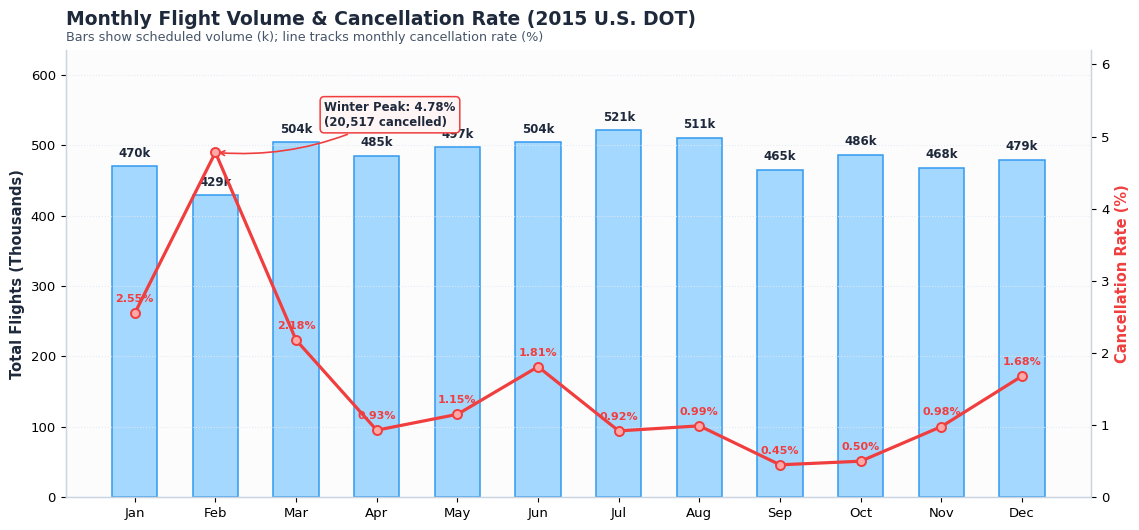

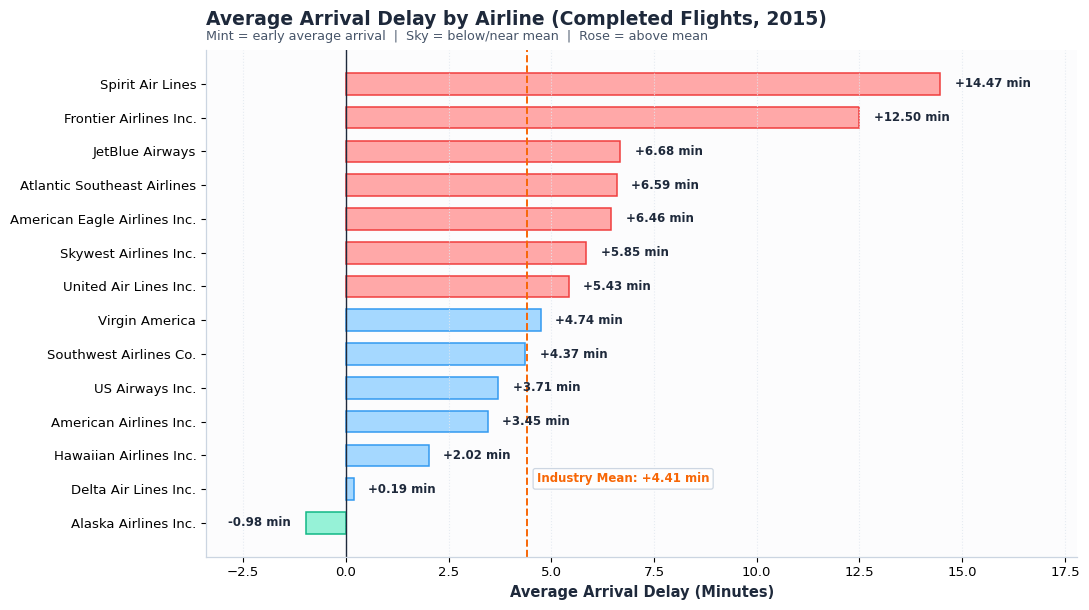

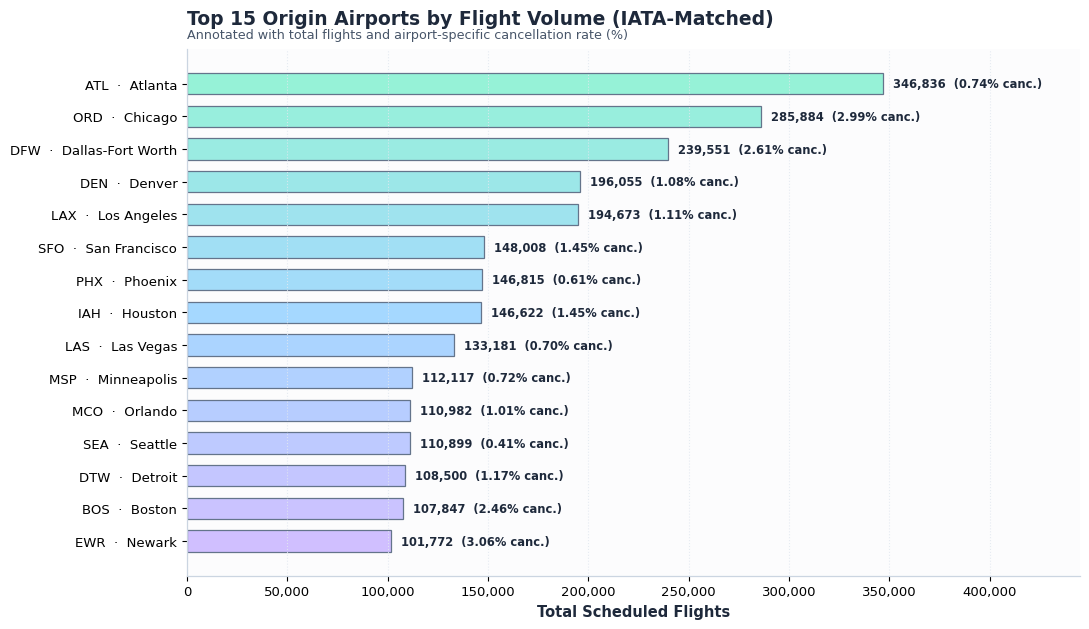

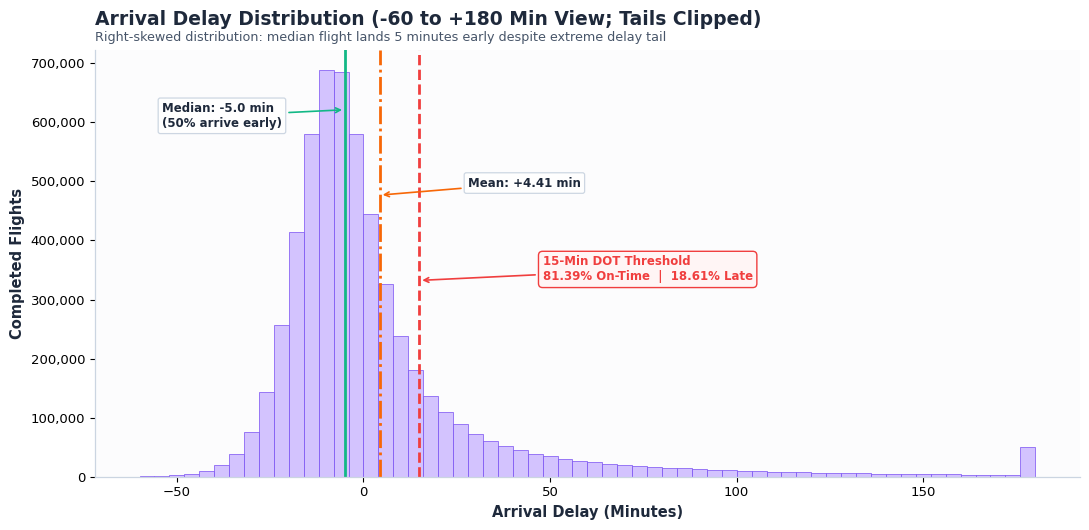

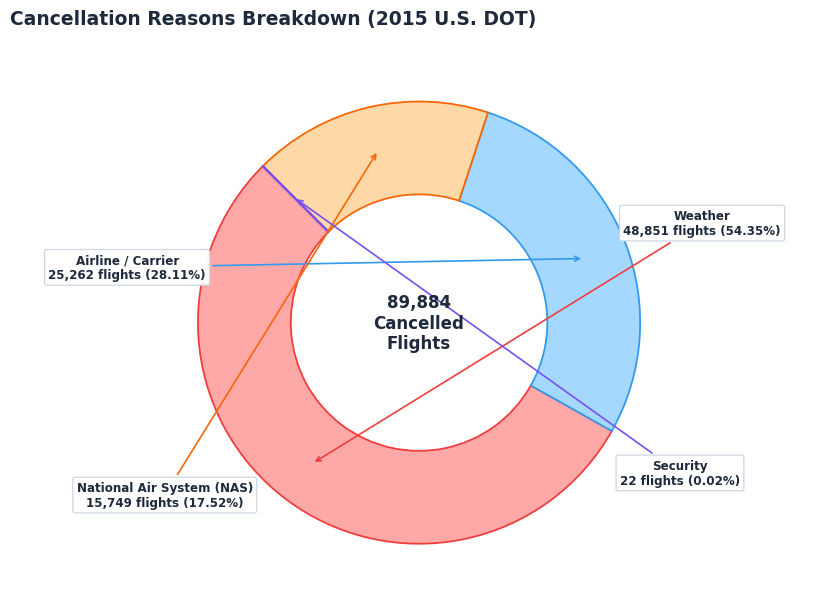

In [9]:
# =========================================================================
# Pastel + Sharp Notation Design System
# =========================================================================
plt.rcParams.update({
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#FCFCFD",
    "axes.edgecolor": "#CBD5E1",
    "axes.linewidth": 0.9,
    "grid.color": "#E2E8F0",
    "grid.linestyle": ":",
    "grid.linewidth": 0.8,
    "font.family": "sans-serif",
    "axes.titleweight": "bold",
    "axes.titlesize": 13.5,
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
})

# Soft Pastel Fills + Sharp Edge/Ink Accents
P_BLUE       = "#A5D8FF"   # Soft sky blue
P_BLUE_EDGE  = "#339AF0"   # Crisp cerulean edge
P_MINT       = "#96F2D7"   # Pastel mint
P_MINT_EDGE  = "#12B886"   # Sharp emerald edge
P_ROSE       = "#FFA8A8"   # Blush rose
P_ROSE_EDGE  = "#F03E3E"   # Sharp crimson edge
P_PEACH      = "#FFD8A8"   # Warm pastel apricot
P_PEACH_EDGE = "#F76707"   # Sharp amber-orange edge
P_LAV        = "#D0BFFF"   # Soft lavender
P_LAV_EDGE   = "#7950F2"   # Sharp violet edge
INK          = "#1E293B"   # High-contrast charcoal ink
MUTED_INK    = "#475569"   # Subtitle / secondary ink

BADGE_STYLE = dict(boxstyle="round,pad=0.32,rounding_size=0.18", facecolor="#FFFFFF", edgecolor="#CBD5E1", linewidth=0.9, alpha=0.96)

# -------------------------------------------------------------------------
# 1. Monthly Flight Volume & Cancellation Rate (Pastel Dual-Axis Combo)
# -------------------------------------------------------------------------
short_months = [m[:3] for m in monthly_summary["MONTH_NAME"]]
fig, ax1 = plt.subplots(figsize=(11.5, 5.4))
bars = ax1.bar(
    short_months, monthly_summary["TOTAL_FLIGHTS"] / 1000,
    color=P_BLUE, edgecolor=P_BLUE_EDGE, linewidth=1.1, width=0.56, label="Total Flights (Thousands)"
)
ax1.set_ylabel("Total Flights (Thousands)", color=INK, fontweight="bold")
ax1.set_ylim(0, 635)
ax1.grid(axis="y", alpha=0.85)
ax1.grid(axis="x", visible=False)

for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 9, f"{h:.0f}k", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=INK)

ax2 = ax1.twinx()
ax2.plot(
    short_months, monthly_summary["CANCELLATION_RATE_PCT"],
    color=P_ROSE_EDGE, marker="o", linewidth=2.3, markersize=6.5,
    markerfacecolor=P_ROSE, markeredgecolor=P_ROSE_EDGE, markeredgewidth=1.4, label="Cancellation Rate (%)"
)
ax2.set_ylabel("Cancellation Rate (%)", color=P_ROSE_EDGE, fontweight="bold")
ax2.set_ylim(0, 6.2)
ax2.grid(False)

for idx, val in enumerate(monthly_summary["CANCELLATION_RATE_PCT"]):
    if idx != 1:  # February gets a dedicated sharp callout badge below
        ax2.annotate(f"{val:.2f}%", (idx, val), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, fontweight="bold", color=P_ROSE_EDGE)

# Sharp editorial callout on February winter spike
feb_val = float(monthly_summary.loc[1, "CANCELLATION_RATE_PCT"])
ax2.annotate(
    f"Winter Peak: {feb_val:.2f}%\n(20,517 cancelled)",
    xy=(1, feb_val), xytext=(2.35, 5.15),
    fontsize=8.5, fontweight="bold", color=INK,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FFF5F5", edgecolor=P_ROSE_EDGE, linewidth=1.1),
    arrowprops=dict(arrowstyle="->", color=P_ROSE_EDGE, lw=1.2, connectionstyle="arc3,rad=-0.15"),
)

ax1.set_title("Monthly Flight Volume & Cancellation Rate (2015 U.S. DOT)", loc="left", pad=18, color=INK)
ax1.text(0, 1.02, "Bars show scheduled volume (k); line tracks monthly cancellation rate (%)", transform=ax1.transAxes, fontsize=9.2, color=MUTED_INK)
sns.despine(ax=ax1, top=True, right=False)
sns.despine(ax=ax2, top=True, right=False)
plt.tight_layout()
plt.savefig(viz_dir / "01_monthly_flight_trend.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 2. Airline-Wise Average Arrival Delay (Pastel Diverging Bar + Sharp Badges)
# -------------------------------------------------------------------------
air_del = airline_summary.sort_values("AVG_ARR_DELAY_MIN", ascending=True)
fills = [P_MINT if v < 0 else (P_BLUE if v <= 5 else P_ROSE) for v in air_del["AVG_ARR_DELAY_MIN"]]
edges = [P_MINT_EDGE if v < 0 else (P_BLUE_EDGE if v <= 5 else P_ROSE_EDGE) for v in air_del["AVG_ARR_DELAY_MIN"]]

fig, ax = plt.subplots(figsize=(11, 6.2))
bars = ax.barh(air_del["AIRLINE_NAME"], air_del["AVG_ARR_DELAY_MIN"], color=fills, edgecolor=edges, linewidth=1.1, height=0.64)
ax.axvline(0, color=INK, linewidth=1.0)
ax.axvline(4.41, color=P_PEACH_EDGE, linestyle="--", linewidth=1.4)
ax.text(4.65, 1.2, "Industry Mean: +4.41 min", fontsize=8.5, fontweight="bold", color=P_PEACH_EDGE, bbox=BADGE_STYLE)

for bar in bars:
    w = bar.get_width()
    offset = 0.35 if w >= 0 else -0.35
    ha = "left" if w >= 0 else "right"
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.2f} min", va="center", ha=ha, fontsize=8.5, fontweight="bold", color=INK)

ax.set_xlim(-3.4, 17.8)
ax.set_title("Average Arrival Delay by Airline (Completed Flights, 2015)", loc="left", pad=18, color=INK)
ax.text(0, 1.02, "Mint = early average arrival  |  Sky = below/near mean  |  Rose = above mean", transform=ax.transAxes, fontsize=9.2, color=MUTED_INK)
ax.set_xlabel("Average Arrival Delay (Minutes)", fontweight="bold", color=INK)
ax.grid(axis="x", alpha=0.85)
ax.grid(axis="y", visible=False)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(viz_dir / "02_airline_wise_delay.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 3. Top 15 Origin Airports by Flight Count (Soft Lavender-Blue Gradient)
# -------------------------------------------------------------------------
top15_apt = airport_top25_summary.head(15).sort_values("TOTAL_FLIGHTS", ascending=True)
apt_labels = top15_apt["IATA_CODE"] + "  ·  " + top15_apt["CITY"]
pastel_grad = sns.blend_palette(["#D0BFFF", "#A5D8FF", "#96F2D7"], n_colors=len(top15_apt))

fig, ax = plt.subplots(figsize=(11, 6.4))
bars = ax.barh(apt_labels, top15_apt["TOTAL_FLIGHTS"], color=pastel_grad, edgecolor="#64748B", linewidth=0.9, height=0.66)
for bar, (_, row) in zip(bars, top15_apt.iterrows()):
    w = bar.get_width()
    ax.text(
        w + 5000, bar.get_y() + bar.get_height()/2,
        f"{int(w):,}  ({row['CANCELLATION_RATE_PCT']:.2f}% canc.)",
        va="center", ha="left", fontsize=8.3, fontweight="bold", color=INK
    )

ax.set_xlim(0, 445_000)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Top 15 Origin Airports by Flight Volume (IATA-Matched)", loc="left", pad=18, color=INK)
ax.text(0, 1.02, "Annotated with total flights and airport-specific cancellation rate (%)", transform=ax.transAxes, fontsize=9.2, color=MUTED_INK)
ax.set_xlabel("Total Scheduled Flights", fontweight="bold", color=INK)
ax.grid(axis="x", alpha=0.85)
ax.grid(axis="y", visible=False)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(viz_dir / "03_airport_flight_count.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 4. Arrival Delay Distribution (Pastel Histogram + Sharp Threshold Callouts)
# -------------------------------------------------------------------------
arr_clipped = completed["ARRIVAL_DELAY"].dropna().clip(-60, 180)
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.hist(arr_clipped, bins=60, color=P_LAV, edgecolor=P_LAV_EDGE, linewidth=0.55, alpha=0.92)
ax.axvline(-5.0, color=P_MINT_EDGE, linestyle="-", linewidth=2.0)
ax.axvline(4.41, color=P_PEACH_EDGE, linestyle="-.", linewidth=2.0)
ax.axvline(15.0, color=P_ROSE_EDGE, linestyle="--", linewidth=2.0)

y_top = ax.get_ylim()[1]
ax.annotate("Median: -5.0 min\n(50% arrive early)", xy=(-5.0, y_top*0.86), xytext=(-54, y_top*0.82), fontsize=8.5, fontweight="bold", color=INK, bbox=BADGE_STYLE, arrowprops=dict(arrowstyle="->", color=P_MINT_EDGE, lw=1.2))
ax.annotate("Mean: +4.41 min", xy=(4.41, y_top*0.66), xytext=(28, y_top*0.68), fontsize=8.5, fontweight="bold", color=INK, bbox=BADGE_STYLE, arrowprops=dict(arrowstyle="->", color=P_PEACH_EDGE, lw=1.2))
ax.annotate("15-Min DOT Threshold\n81.39% On-Time  |  18.61% Late", xy=(15.0, y_top*0.46), xytext=(48, y_top*0.46), fontsize=8.5, fontweight="bold", color=P_ROSE_EDGE, bbox=dict(boxstyle="round,pad=0.35", facecolor="#FFF5F5", edgecolor=P_ROSE_EDGE, lw=1.0), arrowprops=dict(arrowstyle="->", color=P_ROSE_EDGE, lw=1.2))

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Arrival Delay Distribution (-60 to +180 Min View; Tails Clipped)", loc="left", pad=18, color=INK)
ax.text(0, 1.02, "Right-skewed distribution: median flight lands 5 minutes early despite extreme delay tail", transform=ax.transAxes, fontsize=9.2, color=MUTED_INK)
ax.set_xlabel("Arrival Delay (Minutes)", fontweight="bold", color=INK)
ax.set_ylabel("Completed Flights", fontweight="bold", color=INK)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(viz_dir / "04_arrival_delay_distribution.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 5. Cancellation Reasons Breakdown (Pastel Donut + Sharp Leader Callouts)
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.2, 6.2))
donut_fills = [P_ROSE, P_BLUE, P_PEACH, P_LAV]
donut_edges = [P_ROSE_EDGE, P_BLUE_EDGE, P_PEACH_EDGE, P_LAV_EDGE]
wedges, _ = ax.pie(
    cancellation_reasons_summary["CANCELLED_FLIGHTS"],
    startangle=135,
    colors=donut_fills,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2.5},
)
for w, ec in zip(wedges, donut_edges):
    w.set_edgecolor(ec)
    w.set_linewidth(1.3)

label_positions = [(1.28, 0.45), (-1.32, 0.25), (-1.15, -0.78), (1.18, -0.68)]
for idx, (w, (_, row)) in enumerate(zip(wedges, cancellation_reasons_summary.iterrows())):
    ang = (w.theta2 + w.theta1) / 2.0
    x = np.cos(np.deg2rad(ang)) * 0.80
    y = np.sin(np.deg2rad(ang)) * 0.80
    tx, ty = label_positions[idx]
    ax.annotate(
        f"{row['CANCELLATION_REASON']}\n{int(row['CANCELLED_FLIGHTS']):,} flights ({row['SHARE_PCT']:.2f}%)",
        xy=(x, y), xytext=(tx, ty), ha="center", va="center",
        fontsize=8.6, fontweight="bold", color=INK, bbox=BADGE_STYLE,
        arrowprops=dict(arrowstyle="->", color=donut_edges[idx], lw=1.2),
    )

ax.text(0, 0, "89,884\nCancelled\nFlights", ha="center", va="center", fontsize=12, fontweight="bold", color=INK)
ax.set_xlim(-1.85, 1.85)
ax.set_ylim(-1.25, 1.25)
ax.set_title("Cancellation Reasons Breakdown (2015 U.S. DOT)", loc="left", pad=16, color=INK)
plt.tight_layout()
plt.savefig(viz_dir / "05_cancellation_distribution.png", dpi=220)
plt.show()

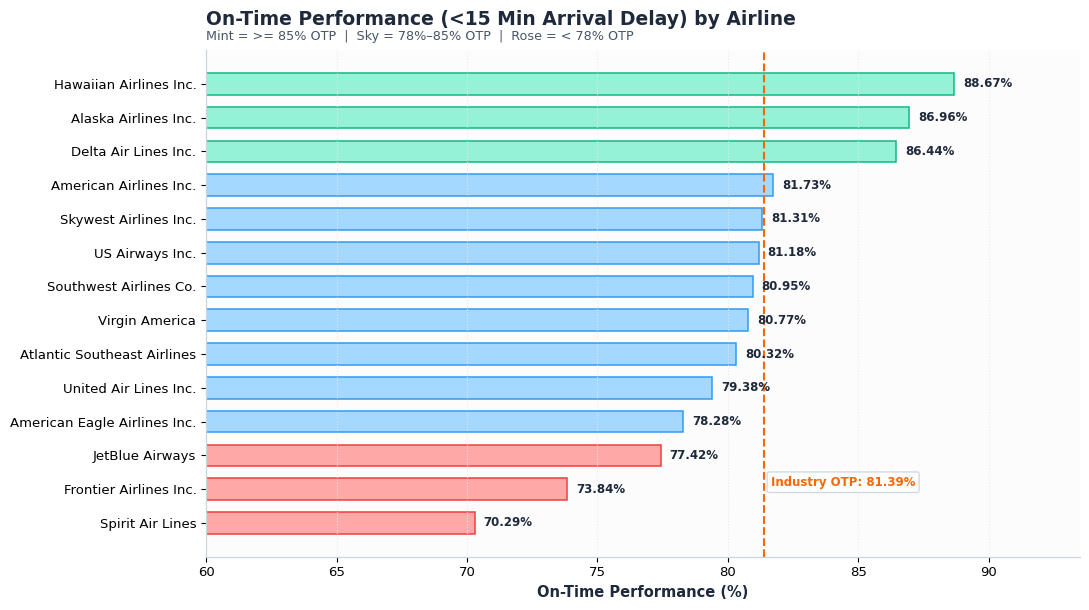

C:\Users\snesh\AppData\Local\Temp\ipykernel_4184\2535260664.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


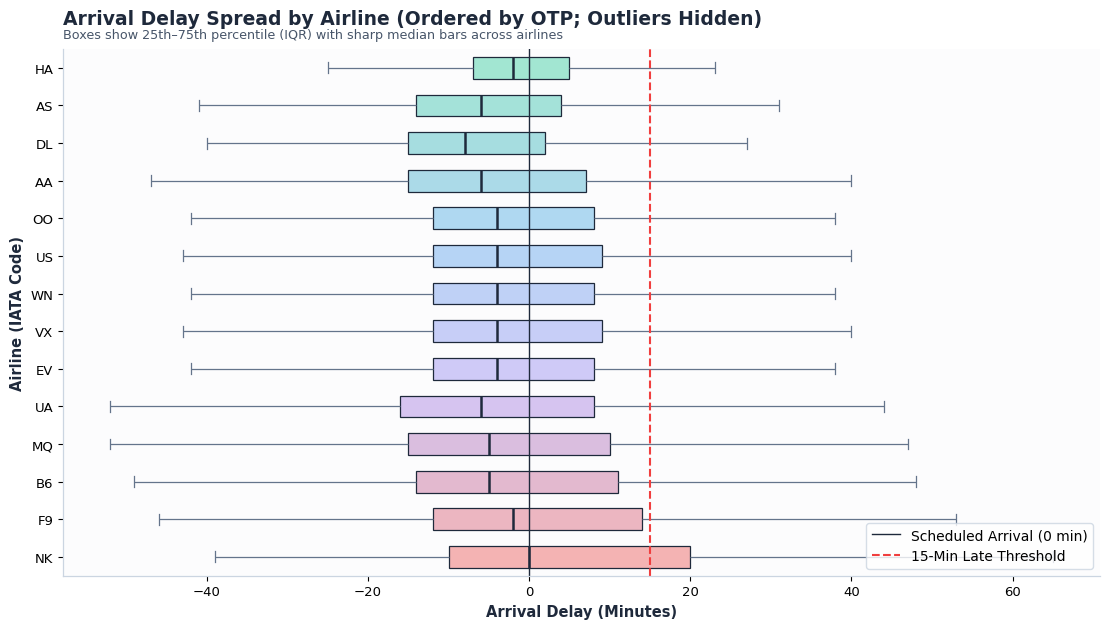

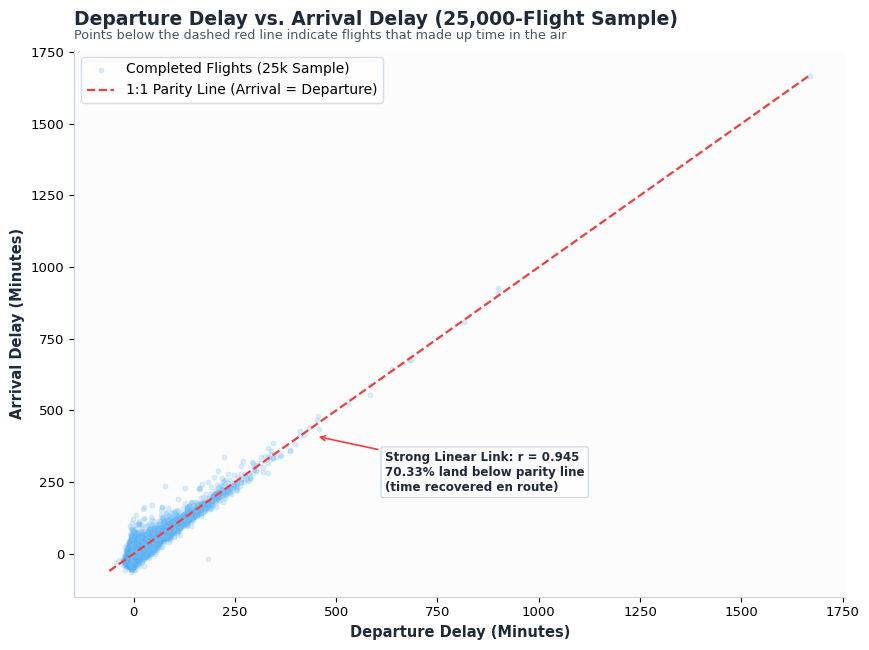

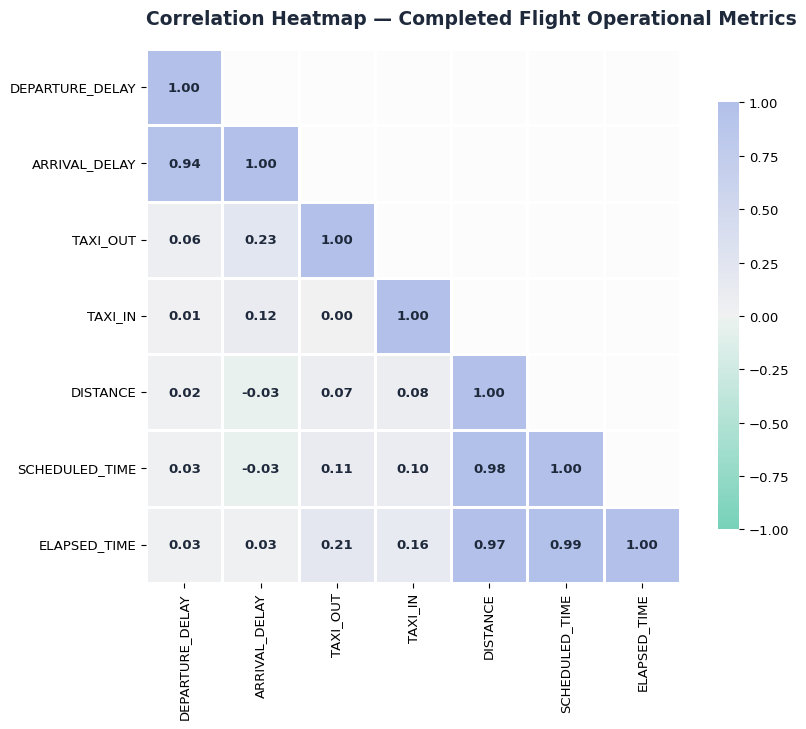

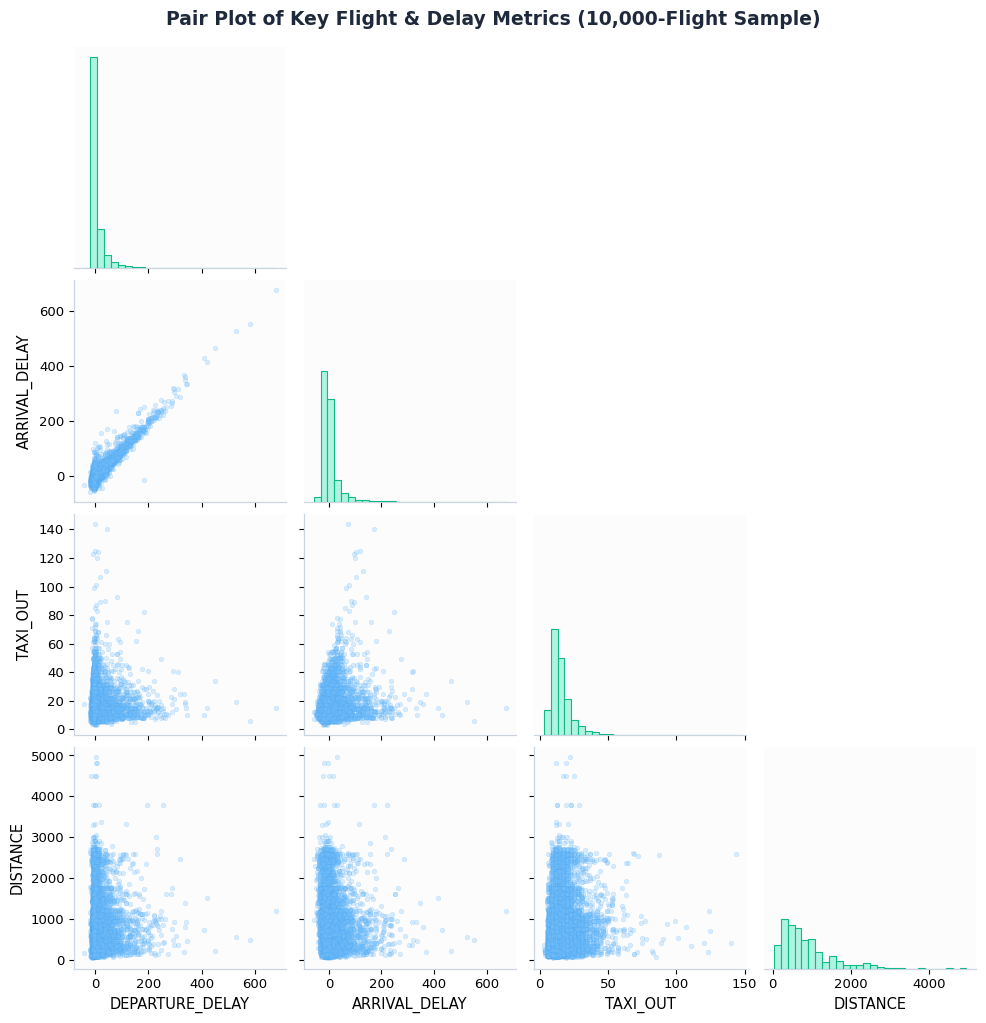

All 10 pastel visualizations with sharp notations saved to: D:\Codenera\Project\Airline_Delay_Analysis\visualizations


In [10]:
SLATE = "#64748B"

# -------------------------------------------------------------------------
# 6. Airline On-Time Performance (<15 Min Arrival Delay)
# -------------------------------------------------------------------------
otp_sorted = airline_summary.sort_values("OTP_PCT", ascending=True)
otp_fills = [P_ROSE if v < 78 else (P_BLUE if v < 85 else P_MINT) for v in otp_sorted["OTP_PCT"]]
otp_edges = [P_ROSE_EDGE if v < 78 else (P_BLUE_EDGE if v < 85 else P_MINT_EDGE) for v in otp_sorted["OTP_PCT"]]

fig, ax = plt.subplots(figsize=(11, 6.2))
bars = ax.barh(otp_sorted["AIRLINE_NAME"], otp_sorted["OTP_PCT"], color=otp_fills, edgecolor=otp_edges, linewidth=1.1, height=0.64)
ax.axvline(81.39, color=P_PEACH_EDGE, linestyle="--", linewidth=1.5)
ax.text(81.65, 1.1, "Industry OTP: 81.39%", fontsize=8.5, fontweight="bold", color=P_PEACH_EDGE, bbox=BADGE_STYLE)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.35, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va="center", ha="left", fontsize=8.5, fontweight="bold", color=INK)

ax.set_xlim(60, 93.5)
ax.set_title("On-Time Performance (<15 Min Arrival Delay) by Airline", loc="left", pad=18, color=INK)
ax.text(0, 1.02, "Mint = >= 85% OTP  |  Sky = 78%–85% OTP  |  Rose = < 78% OTP", transform=ax.transAxes, fontsize=9.2, color=MUTED_INK)
ax.set_xlabel("On-Time Performance (%)", fontweight="bold", color=INK)
ax.grid(axis="x", alpha=0.85)
ax.grid(axis="y", visible=False)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(viz_dir / "06_airline_performance.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 7. Arrival Delay Spread by Airline (Pastel Box Plot + Median Markers)
# -------------------------------------------------------------------------
order_codes = airline_summary["AIRLINE_CODE"].tolist()
box_sample = completed[completed["ARRIVAL_DELAY"].between(-60, 180)].sample(n=min(120_000, len(completed)), random_state=42)
box_palette = sns.blend_palette([P_MINT, P_BLUE, P_LAV, P_ROSE], n_colors=len(order_codes))

fig, ax = plt.subplots(figsize=(11.2, 6.4))
sns.boxplot(
    data=box_sample, x="ARRIVAL_DELAY", y="AIRLINE", order=order_codes,
    showfliers=False, palette=box_palette, width=0.58,
    boxprops=dict(edgecolor=INK, linewidth=0.9),
    medianprops=dict(color=INK, linewidth=1.8),
    whiskerprops=dict(color=SLATE, linewidth=0.9),
    capprops=dict(color=SLATE, linewidth=0.9),
    ax=ax
)
ax.axvline(0, color=INK, linewidth=1.0, label="Scheduled Arrival (0 min)")
ax.axvline(15, color=P_ROSE_EDGE, linestyle="--", linewidth=1.5, label="15-Min Late Threshold")
ax.set_title("Arrival Delay Spread by Airline (Ordered by OTP; Outliers Hidden)", loc="left", pad=18, color=INK)
ax.text(0, 1.02, "Boxes show 25th–75th percentile (IQR) with sharp median bars across airlines", transform=ax.transAxes, fontsize=9.2, color=MUTED_INK)
ax.set_xlabel("Arrival Delay (Minutes)", fontweight="bold", color=INK)
ax.set_ylabel("Airline (IATA Code)", fontweight="bold", color=INK)
ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#CBD5E1")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(viz_dir / "07_delay_distribution_by_airline.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 8. Departure Delay vs. Arrival Delay (Pastel Periwinkle Scatter + Sharp Callouts)
# -------------------------------------------------------------------------
scatter_sample = completed.dropna(subset=["DEPARTURE_DELAY", "ARRIVAL_DELAY"]).sample(n=min(25_000, len(completed)), random_state=42)
fig, ax = plt.subplots(figsize=(8.8, 6.6))
ax.scatter(
    scatter_sample["DEPARTURE_DELAY"], scatter_sample["ARRIVAL_DELAY"],
    alpha=0.28, s=14, color="#74C0FC", edgecolors="#339AF0", linewidths=0.2, label="Completed Flights (25k Sample)"
)
lims = [-60, max(scatter_sample["DEPARTURE_DELAY"].max(), scatter_sample["ARRIVAL_DELAY"].max())]
ax.plot(lims, lims, color=P_ROSE_EDGE, linestyle="--", linewidth=1.6, label="1:1 Parity Line (Arrival = Departure)")

ax.annotate(
    "Strong Linear Link: r = 0.945\n70.33% land below parity line\n(time recovered en route)",
    xy=(450, 410), xytext=(620, 220),
    fontsize=8.6, fontweight="bold", color=INK, bbox=BADGE_STYLE,
    arrowprops=dict(arrowstyle="->", color=P_ROSE_EDGE, lw=1.2),
)

ax.set_title("Departure Delay vs. Arrival Delay (25,000-Flight Sample)", loc="left", pad=18, color=INK)
ax.text(0, 1.02, "Points below the dashed red line indicate flights that made up time in the air", transform=ax.transAxes, fontsize=9.2, color=MUTED_INK)
ax.set_xlabel("Departure Delay (Minutes)", fontweight="bold", color=INK)
ax.set_ylabel("Arrival Delay (Minutes)", fontweight="bold", color=INK)
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#CBD5E1")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(viz_dir / "08_dep_vs_arr_delay_scatter.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 9. Correlation Heatmap (Soft Pastel Diverging Palette + Crisp Borders)
# -------------------------------------------------------------------------
corr_cols = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN", "DISTANCE", "SCHEDULED_TIME", "ELAPSED_TIME"]
corr = completed[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
pastel_div = sns.diverging_palette(165, 255, s=65, l=78, as_cmap=True)

fig, ax = plt.subplots(figsize=(9.2, 7.4))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap=pastel_div, vmin=-1, vmax=1, center=0,
    annot_kws={"size": 9.5, "weight": "bold", "color": INK},
    square=True, linewidths=1.8, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("Correlation Heatmap — Completed Flight Operational Metrics", loc="left", pad=18, color=INK)
plt.tight_layout()
plt.savefig(viz_dir / "09_correlation_heatmap.png", dpi=220)
plt.show()

# -------------------------------------------------------------------------
# 10. Pair Plot (Pastel Mint & Sky Corner Pair Plot)
# -------------------------------------------------------------------------
pair_cols = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "DISTANCE"]
pair_sample = completed[pair_cols].dropna().sample(n=min(10_000, len(completed)), random_state=42)
pair_grid = sns.pairplot(
    pair_sample,
    corner=True,
    plot_kws={"alpha": 0.28, "s": 12, "color": "#74C0FC", "edgecolor": "#339AF0", "linewidth": 0.2},
    diag_kws={"color": P_MINT, "edgecolor": P_MINT_EDGE, "linewidth": 0.8, "bins": 28},
)
pair_grid.figure.suptitle("Pair Plot of Key Flight & Delay Metrics (10,000-Flight Sample)", y=1.02, fontsize=13.5, fontweight="bold", color=INK)
pair_grid.savefig(viz_dir / "10_pairplot.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close("all")

print("All 10 pastel visualizations with sharp notations saved to:", viz_dir)

## 6. SQL Database & Business Queries (`sql/`)
Connect to `dataset/cleaned/airline_delays.db` (building it automatically only if missing) and execute all 10 business queries documented in `sql/01_core_kpis_and_delays.sql` and `sql/02_rankings_trends_and_extremes.sql`.

In [11]:
db_path = cleaned_path / "airline_delays.db"
conn = sqlite3.connect(db_path)
conn.execute("PRAGMA journal_mode = WAL;")
conn.execute("PRAGMA synchronous = NORMAL;")

already_loaded = False
try:
    if conn.execute("SELECT COUNT(*) FROM flights").fetchone()[0] == 5_819_079:
        already_loaded = True
        print("SQLite flights table already populated (5,819,079 rows) — running queries directly.")
except sqlite3.OperationalError:
    pass

if not already_loaded:
    conn.execute("DROP TABLE IF EXISTS flights;")
    airlines.to_sql("airlines", conn, if_exists="replace", index=False)
    airports.to_sql("airports", conn, if_exists="replace", index=False)
    pf = pq.ParquetFile(cleaned_file)
    for batch in pf.iter_batches(batch_size=200_000):
        chunk = batch.to_pandas()
        chunk["FLIGHT_DATE"] = pd.to_datetime(chunk["FLIGHT_DATE"]).dt.strftime("%Y-%m-%d")
        chunk["FLIGHT_STATUS"] = chunk["FLIGHT_STATUS"].astype(str)
        chunk["IS_LATE_15"] = chunk["IS_LATE_15"].map({True: 1, False: 0}).astype("float64")
        chunk["HAS_NUMERIC_AIRPORT_ID"] = chunk["HAS_NUMERIC_AIRPORT_ID"].map({True: 1, False: 0}).astype("float64")
        chunk.to_sql("flights", conn, if_exists="append", index=False)
    conn.commit()

for sql_file in sorted(sql_dir.glob("*.sql")):
    print(f"\n=== Executing {sql_file.name} ===")
    queries = [q.strip() for q in sql_file.read_text(encoding="utf-8").split(";") if q.strip()]
    for q in queries:
        display(pd.read_sql_query(q, conn).head(10))

conn.close()

SQLite flights table already populated (5,819,079 rows) — running queries directly.

=== Executing 01_core_kpis_and_delays.sql ===


,total_flights
0,5819079


,avg_arrival_delay_min
0,4.41


,airline_code,airline_name,delayed_flights_15plus
0,WN,Southwest Airlines Co.,236626
1,AA,American Airlines Inc.,130279
2,DL,Delta Air Lines Inc.,118023
3,EV,Atlantic Southeast Airlines,109184
4,OO,Skywest Airlines Inc.,107795
5,UA,United Air Lines Inc.,104722
6,MQ,American Eagle Airlines Inc.,60547
7,B6,JetBlue Airways,59175
8,US,US Airways Inc.,36549
9,NK,Spirit Air Lines,34221


,airport_code,airport_name,city,state,completed_flights,avg_departure_delay_min,avg_arrival_delay_min
0,ATL,Hartsfield-Jackson Atlanta International Airport,Atlanta,GA,343506,9.29,3.05
1,ORD,Chicago O'Hare International Airport,Chicago,IL,276554,14.03,8.60
2,DFW,Dallas/Fort Worth International Airport,Dallas-Fort Worth,TX,232647,11.41,6.92
3,DEN,Denver International Airport,Denver,CO,193402,11.76,7.19
4,LAX,Los Angeles International Airport,Los Angeles,CA,192003,10.62,5.72
5,PHX,Phoenix Sky Harbor International Airport,Phoenix,AZ,145552,8.63,4.39
6,SFO,San Francisco International Airport,San Francisco,CA,145491,11.16,5.75
7,IAH,George Bush Intercontinental Airport,Houston,TX,144019,11.48,7.38
8,LAS,McCarran International Airport,Las Vegas,NV,131937,10.90,6.02
9,MSP,Minneapolis-Saint Paul International Airport,Minneapolis,MN,111055,7.21,1.97


,total_flights,cancelled_flights,cancellation_rate_pct
0,5819079,89884,1.54


... (2 outputs left out)

,month,total_flights,completed_flights,cancelled_flights,cancellation_rate_pct,avg_arrival_delay_min
0,1,469968,457013,11982,2.55,5.81
1,2,429191,407663,20517,4.78,8.32
2,3,504312,492138,11002,2.18,4.92
3,4,485151,479251,4520,0.93,3.16
4,5,496993,489641,5694,1.15,4.49
5,6,503897,492847,9120,1.81,9.60
6,7,520718,514384,4806,0.92,6.43
7,8,510536,503956,5052,0.99,4.61
8,9,464946,462153,2075,0.45,-0.77
9,10,486165,482878,2454,0.50,-0.78


,otp_rank,airline_code,airline_name,completed_flights,on_time_flights,on_time_pct
0,1,HA,Hawaiian Airlines Inc.,76041,67423,88.67
1,2,AS,Alaska Airlines Inc.,171439,149087,86.96
2,3,DL,Delta Air Lines Inc.,870275,752252,86.44
3,4,AA,American Airlines Inc.,712935,582656,81.73
4,5,OO,Skywest Airlines Inc.,576814,469019,81.31
5,6,US,US Airways Inc.,194223,157674,81.18
6,7,WN,Southwest Airlines Co.,1242403,1005777,80.95
7,8,VX,Virgin America,61248,49470,80.77
8,9,EV,Atlantic Southeast Airlines,554752,445568,80.32
9,10,UA,United Air Lines Inc.,507762,403040,79.38


,overall_avg_departure_delay_min
0,9.29


,flight_date,airline_code,airline_name,flight_number,origin_airport,destination_airport,departure_delay_min,arrival_delay_min
0,2015-01-23,AA,American Airlines Inc.,1322,BHM,DFW,1988.0,1971.0
1,2015-08-01,AA,American Airlines Inc.,96,RIC,DFW,1878.0,1898.0
2,2015-09-13,AA,American Airlines Inc.,1063,SAN,DFW,1670.0,1665.0
3,2015-11-27,AA,American Airlines Inc.,2559,DTW,ORD,1631.0,1638.0
4,2015-07-13,AA,American Airlines Inc.,1319,IND,LAX,1625.0,1636.0
5,2015-12-31,AA,American Airlines Inc.,2214,ABQ,DFW,1649.0,1636.0
6,2015-02-28,AA,American Airlines Inc.,1312,STL,MIA,1587.0,1627.0
7,2015-03-24,AA,American Airlines Inc.,1279,OMA,DFW,1609.0,1598.0
8,2015-01-18,AA,American Airlines Inc.,224,LAS,LAX,1604.0,1593.0
9,2015-03-04,AA,American Airlines Inc.,270,HNL,LAX,1589.0,1576.0


## 7. Automated PDF Report & Power BI Summary Exports (`reports/` & `powerbi/`)
Regenerate `reports/airline_delay_analysis_report.pdf` with the pastel visualizations and sync all 5 Power BI summary CSVs (`airline_summary.csv`, `airport_top25_summary.csv`, `monthly_summary.csv`, `cancellation_reasons_summary.csv`, and `delay_causes_summary.csv`) so every deliverable on disk stays 100% consistent.

In [12]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import letter
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak

# 1. Sync all 5 Power BI summary CSVs
airline_summary.to_csv(pbi_dir / "airline_summary.csv", index=False)
airport_top25_summary.to_csv(pbi_dir / "airport_top25_summary.csv", index=False)
monthly_summary.to_csv(pbi_dir / "monthly_summary.csv", index=False)
cancellation_reasons_summary.to_csv(pbi_dir / "cancellation_reasons_summary.csv", index=False)
delay_causes_summary.to_csv(pbi_dir / "delay_causes_summary.csv", index=False)
print("Synced all 5 Power BI summary CSVs in:", pbi_dir)

# 2. Rebuild PDF report embedding the pastel charts
pdf_path = reports_dir / "airline_delay_analysis_report.pdf"
doc = SimpleDocTemplate(str(pdf_path), pagesize=letter, leftMargin=0.65*inch, rightMargin=0.65*inch, topMargin=0.65*inch, bottomMargin=0.65*inch)
styles = getSampleStyleSheet()
title_style = ParagraphStyle("ReportTitle", parent=styles["Heading1"], fontSize=18, spaceAfter=8, textColor=colors.HexColor("#102A43"))
h2_style = ParagraphStyle("SectionHeading", parent=styles["Heading2"], fontSize=13, spaceBefore=12, spaceAfter=6, textColor=colors.HexColor("#1F4E78"))
body_style = ParagraphStyle("BodyTextCustom", parent=styles["Normal"], fontSize=10, leading=14, spaceAfter=6)
caption_style = ParagraphStyle("ChartCaption", parent=styles["Normal"], fontSize=9, textColor=colors.HexColor("#486581"), spaceBefore=3, spaceAfter=10)

story = [
    Paragraph("Airline Passenger & Flight Delay Analysis (2015 U.S. DOT)", title_style),
    Paragraph("<b>Scope & Limitations:</b> Based on historical 2015 U.S. DOT flight records (5,819,079 flights; 14 airlines) rather than current Indian airline operations or direct passenger headcounts. 486,165 records use numeric DOT airport IDs rather than 3-letter IATA codes.", body_style),
    Paragraph("Executive KPI Summary", h2_style),
]

kpi_data = [
    ["Metric", "Value", "Notes"],
    ["Total Flights", "5,819,079", "5,714,008 completed (98.19%); 89,884 cancelled; 15,187 diverted"],
    ["Cancellation Rate", "1.54%", "Cancelled flights / Total flights x 100"],
    ["Avg Departure Delay", "9.29 min", "Completed flights (median: -2.0 min; max: 1,988.0 min)"],
    ["Avg Arrival Delay", "4.41 min", "Completed flights (median: -5.0 min; max: 1,971.0 min)"],
    ["On-Time Performance", "81.39%", "Completed flights with arrival delay < 15 min (18.61% late)"],
]
kpi_table = Table(kpi_data, colWidths=[1.8*inch, 1.3*inch, 4.1*inch])
kpi_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E78")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
    ("FONTSIZE", (0, 0), (-1, -1), 9),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.HexColor("#BCCCDC")),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#F0F4F8")]),
    ("PADDING", (0, 0), (-1, -1), 6),
]))
story.extend([kpi_table, Spacer(1, 10)])

story.append(Paragraph("Key Business Insights", h2_style))
for item in [
    "<b>Departure vs. Arrival Delay:</b> Strong correlation (r = 0.945), yet 70.33% (4,018,409) of completed flights recovered time en route (ARRIVAL_DELAY &lt; DEPARTURE_DELAY).",
    "<b>Delay Root Causes (15+ Min Late Flights):</b> Late Aircraft (39.84%) and Airline / Carrier (32.20%) drive over 72% of recorded delay minutes, ahead of Air System (22.88%), Weather (4.95%), and Security (0.13%).",
    "<b>Cancellation Drivers:</b> Weather accounts for 54.35% (48,851) of cancellations, followed by Airline / Carrier (28.11%; 25,262) and National Air System (17.52%; 15,749).",
    "<b>Airline & Airport Spread:</b> On-time performance spans from Hawaiian (88.67%), Alaska (86.96%), and Delta (86.44%) down to Spirit (70.29%); ATL leads IATA-matched origin volume (346,836 flights).",
]:
    story.append(Paragraph(f"&bull; {item}", body_style))

story.append(Paragraph("Recommendations", h2_style))
for item in [
    "<b>Protect Turnaround Buffers & Reserve Aircraft:</b> Target tight turnaround banks and stage standby aircraft at major hubs to curb Late Aircraft (39.84%) and Carrier (32.20%) delay minutes.",
    "<b>Audit High-Cancellation Carriers & Hubs:</b> Focus reliability improvements on carrier-driven cancellations (28.11%) and congested hubs such as EWR, ORD, and DFW.",
    "<b>Track Medians & Tail Percentiles Alongside Mean/OTP:</b> Pair average delay and &lt; 15 min OTP with median and 95th-percentile delay tracking so extreme outliers do not mask typical performance.",
]:
    story.append(Paragraph(f"&bull; {item}", body_style))

story.append(PageBreak())
story.append(Paragraph("Visualizations Appendix", h2_style))

charts_info = [
    ("01_monthly_flight_trend.png", "Figure 1: Monthly flight volume vs. cancellation rate across 2015."),
    ("02_airline_wise_delay.png", "Figure 2: Average arrival delay by airline on completed flights."),
    ("03_airport_flight_count.png", "Figure 3: Top 15 IATA-matched origin airports by flight count."),
    ("04_arrival_delay_distribution.png", "Figure 4: Arrival delay distribution (-60 to +180 min view; tails clipped)."),
    ("05_cancellation_distribution.png", "Figure 5: Breakdown of cancelled flights by cancellation reason."),
    ("06_airline_performance.png", "Figure 6: On-time performance (< 15 min arrival delay) by airline."),
    ("07_delay_distribution_by_airline.png", "Figure 7: Arrival delay IQR spread by airline (extreme outliers hidden)."),
    ("08_dep_vs_arr_delay_scatter.png", "Figure 8: Departure delay vs. arrival delay (25,000-flight sample with 1:1 line)."),
    ("09_correlation_heatmap.png", "Figure 9: Correlation heatmap across completed-flight numeric metrics."),
    ("10_pairplot.png", "Figure 10: Corner pair plot of key delay, taxi, and distance variables (10,000 sample)."),
]
for filename, caption in charts_info:
    img_path = viz_dir / filename
    if img_path.exists():
        img = RLImage(str(img_path))
        scale = min((7.1 * inch) / img.imageWidth, (4.2 * inch) / img.imageHeight)
        img.drawWidth *= scale
        img.drawHeight *= scale
        story.extend([img, Paragraph(caption, caption_style)])

doc.build(story)
print(f"Updated PDF report saved to: {pdf_path} ({pdf_path.stat().st_size / 1024:.1f} KB)")

Synced all 5 Power BI summary CSVs in: D:\Codenera\Project\Airline_Delay_Analysis\powerbi
Updated PDF report saved to: D:\Codenera\Project\Airline_Delay_Analysis\reports\airline_delay_analysis_report.pdf (2257.1 KB)


In [1]:
import pandas as pd
from pathlib import Path

pbi_dir = Path(r"D:\Codenera\Project\Airline_Delay_Analysis\powerbi")
xlsx_path = pbi_dir / "powerbi_tables.xlsx"

csv_files = [
    "airline_summary.csv",
    "airport_top25_summary.csv",
    "cancellation_reasons_summary.csv",
    "delay_causes_summary.csv",
    "monthly_summary.csv",
]

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    for fname in csv_files:
        sheet_name = fname.replace(".csv", "")[:31]
        pd.read_csv(pbi_dir / fname).to_excel(writer, sheet_name=sheet_name, index=False)

print("Created workbook:", xlsx_path)

Created workbook: D:\Codenera\Project\Airline_Delay_Analysis\powerbi\powerbi_tables.xlsx
